In [21]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
project_root = next(
    p for p in [Path.cwd(), *Path.cwd().parents]
    if (p / ".env").exists()
)
PROCESSED_DIR = project_root / "data" / "processed"

In [ ]:
df = pd.read_csv(
    PROCESSED_DIR / "btc_spy_daily.csv",
    index_col="date",
    parse_dates=True
)

,price_btc,price_spy
date,,
2013-12-27,735.07,148.583038
2013-12-30,756.13,148.558716
2013-12-31,754.01,149.261826
2014-01-02,802.39,147.831390
2014-01-03,818.72,147.807129


In [ ]:
df["normalised_btc"] = df["price_btc"] / df["price_btc"].iloc[0]
df["normalised_spy"] = df["price_spy"] / df["price_spy"].iloc[0]

,price_btc,price_spy,normalised_btc,normalised_spy
date,,,,
2013-12-27,735.07,148.583038,1.000000,1.000000
2013-12-30,756.13,148.558716,1.028650,0.999836
2013-12-31,754.01,149.261826,1.025766,1.004568
2014-01-02,802.39,147.831390,1.091583,0.994941
2014-01-03,818.72,147.807129,1.113799,0.994778


In [ ]:
INITIAL_INVESTMENT = 100.0
df["value_btc"] = df["normalised_btc"] * INITIAL_INVESTMENT
df["value_spy"] = df["normalised_spy"] * INITIAL_INVESTMENT

,price_btc,price_spy,normalised_btc,normalised_spy,value_btc,value_spy
date,,,,,,
2013-12-27,735.07,148.583038,1.000000,1.000000,100.000000,100.000000
2013-12-30,756.13,148.558716,1.028650,0.999836,102.865033,99.983630
2013-12-31,754.01,149.261826,1.025766,1.004568,102.576625,100.456840
2014-01-02,802.39,147.831390,1.091583,0.994941,109.158311,99.494123
2014-01-03,818.72,147.807129,1.113799,0.994778,111.379869,99.477794


In [9]:
final_value_btc = df["value_btc"].iloc[-1]
final_value_spy = df["value_spy"].iloc[-1]
profit_btc = final_value_btc - INITIAL_INVESTMENT
profit_spy = final_value_spy - INITIAL_INVESTMENT
total_return_btc = profit_btc / INITIAL_INVESTMENT * 100.0
total_return_spy = profit_spy / INITIAL_INVESTMENT * 100.0

In [18]:
summary = pd.DataFrame(
    {
        "Final value": [final_value_btc, final_value_spy],
        "Profit": [profit_btc, profit_spy],
        "Total return": [total_return_btc, total_return_spy],
    },
    index=["BTC", "SPY"],
)

styled_summary = summary.style.format({
    "Final value": "${:,.2f}",
    "Profit": "${:,.2f}",
    "Total return": "{:,.2f}%",
})
styled_summary

,Final value,Profit,Total return
BTC,"$10,013.70","$9,913.70","9,913.70%"
SPY,$510.92,$410.92,410.92%


In [15]:
RESULTS_DIR = project_root / "results"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

In [19]:
summary.to_csv(RESULTS_DIR / "investment_growth_summary.csv")
styled_summary.to_html(RESULTS_DIR / "investment_growth_summary.html")

In [20]:
df[["value_btc", "value_spy"]].to_csv(
    RESULTS_DIR / "investment_growth_history.csv"
)

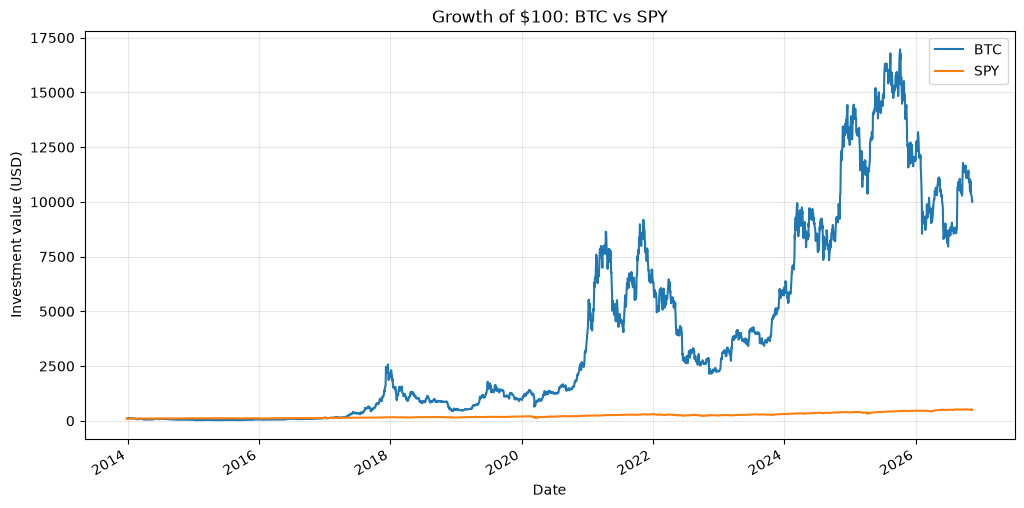

In [22]:
ax = df[["value_btc", "value_spy"]].plot(figsize=(12, 6))
ax.set_title(f"Growth of ${INITIAL_INVESTMENT:,.0f}: BTC vs SPY")
ax.set_xlabel("Date")
ax.set_ylabel("Investment value (USD)")
ax.legend(["BTC", "SPY"])
ax.grid(True, alpha=0.3)

In [23]:
fig = ax.get_figure()
fig.tight_layout()
fig.savefig(RESULTS_DIR / "investment_growth.png", dpi=300)
plt.show()

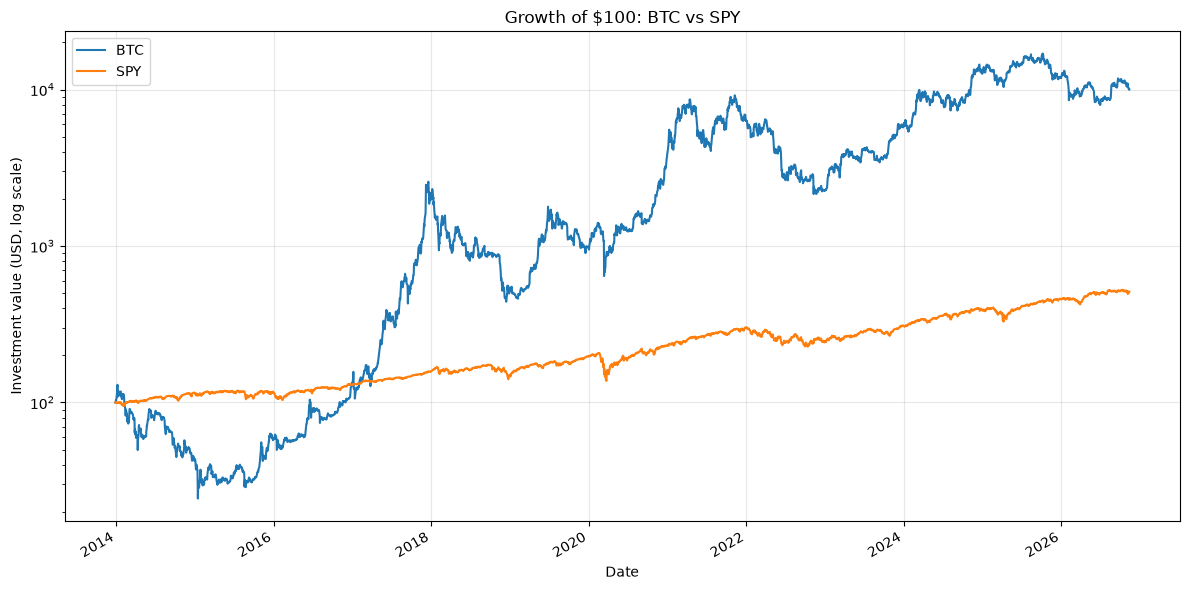

In [25]:
ax_log = df[["value_btc", "value_spy"]].plot(figsize=(12, 6))

ax_log.set_yscale("log")
ax_log.set_title(f"Growth of ${INITIAL_INVESTMENT:,.0f}: BTC vs SPY")
ax_log.set_xlabel("Date")
ax_log.set_ylabel("Investment value (USD, log scale)")
ax_log.legend(["BTC", "SPY"])
ax_log.grid(True, alpha=0.3)

fig_log = ax_log.get_figure()
fig_log.tight_layout()
fig_log.savefig(
    RESULTS_DIR / "investment_growth_log.png",
    dpi=300,
)
plt.show()